In [749]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [834]:
df = pd.read_csv("used_cars.csv")

In [836]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [752]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


In [753]:
df.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

In [754]:
df.nunique()

brand             57
model           1898
model_year        34
milage          2818
fuel_type          7
engine          1146
transmission      62
ext_col          319
int_col          156
accident           2
clean_title        1
price           1569
dtype: int64

In [755]:
lis=['brand','model','fuel_type','engine','transmission','ext_col','int_col','accident']

In [756]:
for i in lis:
    print(df[i].value_counts())
    print('----------------------------')

brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Tesla             87
Kia               76
Hyundai           72
Mazda             64
Acura             64
Subaru            64
Honda             63
Volkswagen        59
INFINITI          59
Lincoln           52
Jaguar            47
Volvo             38
Maserati          34
Bentley           33
MINI              33
Buick             30
Chrysler          28
Lamborghini       26
Mitsubishi        20
Genesis           20
Alfa              19
Rivian            17
Hummer            16
Pontiac           15
Ferrari           12
Rolls-Royce       11
Aston              9
McLaren            6
Scion              6
FIAT               5
Saturn             5
Lotus              4
Lucid  

### DATA CLEANING AND VISUALIZATION

In [758]:
df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [759]:
df['price'] = df['price'].str.replace("$","",regex=False).str.replace(",","",regex=False).astype(float)
df['milage'] = df['milage'].str.replace(" mi.","",regex=False).str.replace(",","",regex=False).astype(float)

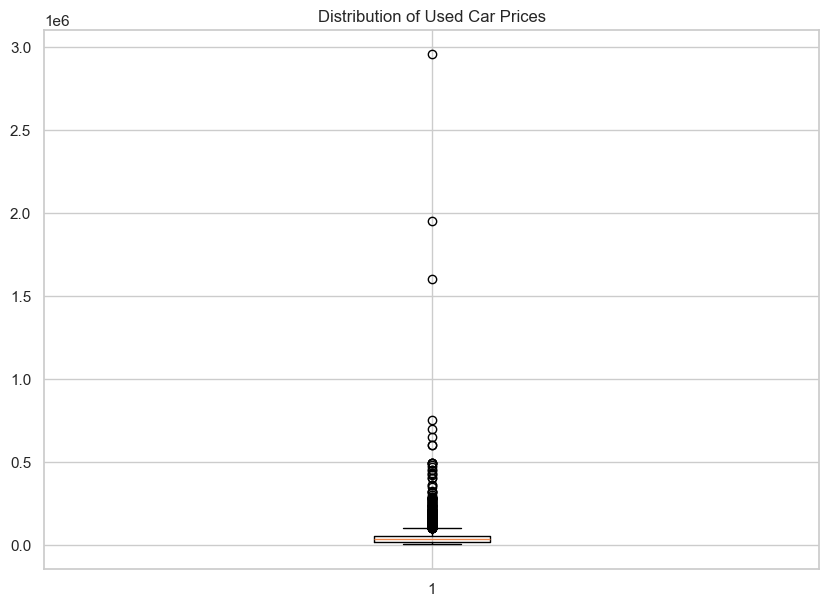

In [760]:
plt.figure(figsize=(10,7))
plt.boxplot(x=df['price'])
plt.title("Distribution of Used Car Prices")
plt.show()

In [761]:
print("Price Percentiles:")
print(df['price'].quantile([0.50, 0.90, 0.95, 0.99, 1.0]))

Price Percentiles:
0.50      31000.00
0.90      79999.00
0.95     111600.00
0.99     272713.28
1.00    2954083.00
Name: price, dtype: float64


###### As we can see that there is significant hike for last 0.1 quantile 
###### therefore we should keep only rows that does not contain outlier 

In [763]:
p99 = df['price'].quantile(0.99)
df_clean = df[df['price'] <= p99].copy()

In [764]:
#df = df.drop(columns=['clean_title'])
df['fuel_type'] = df['fuel_type'].fillna('Unknown')
df['accident'] = df['accident'].fillna('Unknown')

In [765]:
df_clean.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     586
price             0
dtype: int64

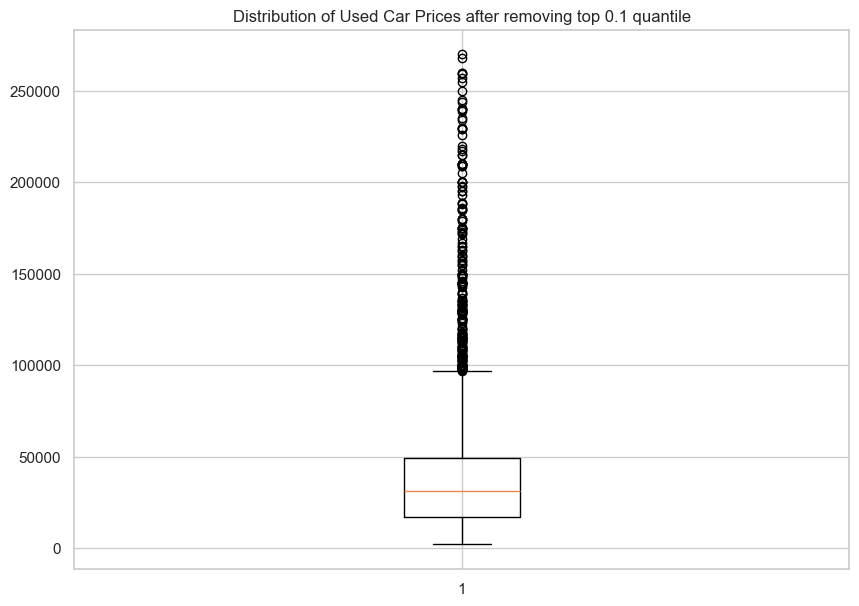

In [766]:
plt.figure(figsize=(10,7))
plt.boxplot(x=df_clean['price'])
plt.title("Distribution of Used Car Prices after removing top 0.1 quantile")
plt.show()

###### We can see that the data is now not skewed

In [768]:
print(f"Original Row Count: {len(df)}")
print(f"Cleaned Row Count: {len(df_clean)}")
print(f"Rows Dropped: {len(df) - len(df_clean)}")
print(f"Old Maximum Price: ${df['price'].max():,.0f}")
print(f"New Maximum Price: ${df_clean['price'].max():,.0f}")

Original Row Count: 4009
Cleaned Row Count: 3968
Rows Dropped: 41
Old Maximum Price: $2,954,083
New Maximum Price: $269,991


##### The biggest threat to this model right now is High Cardinality. The model column has 1,898 unique values, and engine has 1,146. If I blindly apply One-Hot Encoding, I will create over 3,000 new columns. My Streamlit app will crash from memory overload during deployment

In [770]:
# 'clean_title' has no variance. 'engine' is fragmented and redundant to 'model'.
df_clean = df_clean.drop(columns=['clean_title', 'engine'])

In [771]:
def group_rare_categories(series,threshold = 0.01):
    value_counts = series.value_counts(normalize=True)
    rare_models = value_counts[value_counts < threshold].index

    return series.replace(rare_models,"Other")

In [772]:
cols_to_group = ['brand', 'ext_col', 'int_col', 'transmission']
for col in cols_to_group:
    df_clean[col] = group_rare_categories(df_clean[col])

In [773]:
old_unique = df.nunique()
new_unique = df_clean.nunique()
print(old_unique)
print("\n\n\n")
print(new_unique)

brand             57
model           1898
model_year        34
milage          2818
fuel_type          8
engine          1146
transmission      62
ext_col          319
int_col          156
accident           3
clean_title        1
price           1569
dtype: int64




brand             27
model           1878
model_year        34
milage          2783
fuel_type          7
transmission      19
ext_col           10
int_col           10
accident           2
price           1532
dtype: int64


###### Target Encoding for 'model' column as it is too fragmented therefore we can't use one-hot encodoing neither we can drop it entirly as 
###### we already dropped the engine column which is redundant of this column, and it is major price decider column
###### so we will use target encoding and replace with avg historical price of the models

In [775]:
model_mean_price = df_clean.groupby('model')['price'].mean()
df_clean['model_encoded'] = df_clean['model'].map(model_mean_price)
df_clean = df_clean.drop(columns=['model'])

C:\Users\hp\AppData\Local\Temp\ipykernel_8768\3655728397.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


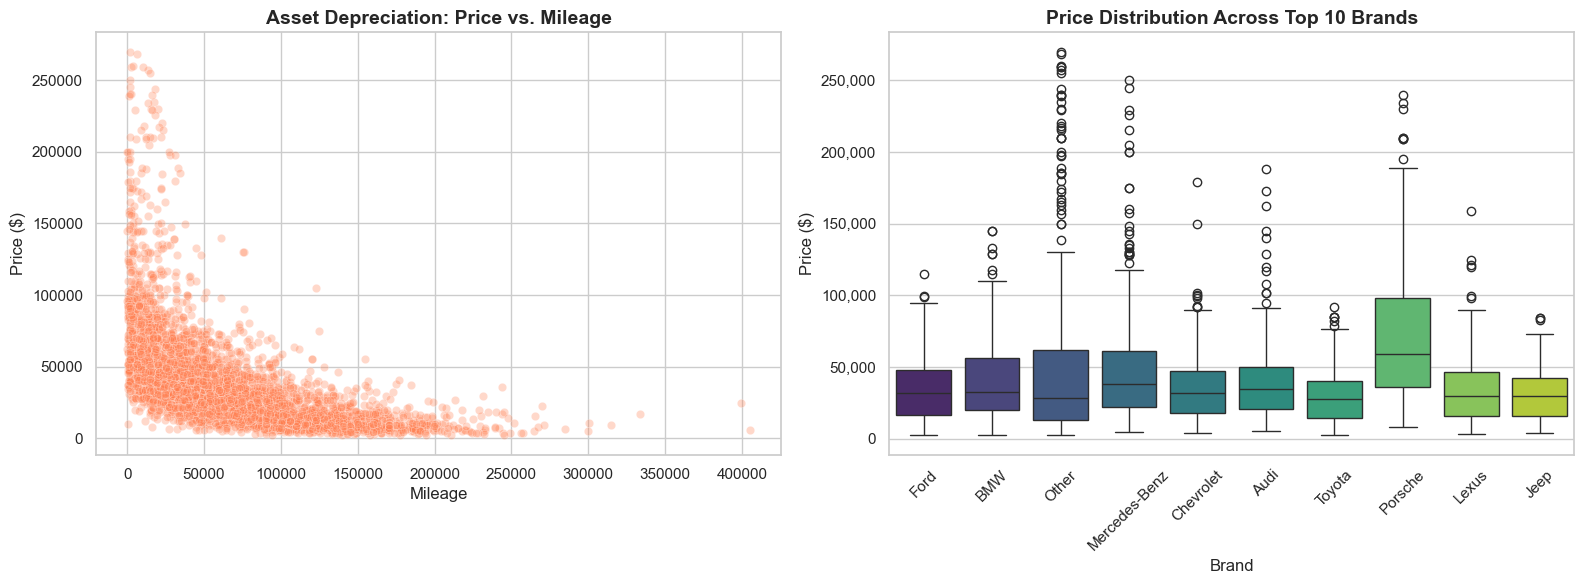

In [832]:
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=df_clean, x='milage', y='price', 
    alpha=0.3, color='coral', ax=axes[0]
)
axes[0].set_title('Asset Depreciation: Price vs. Mileage', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Mileage')
axes[0].set_ylabel('Price ($)')

top_brands = df_clean['brand'].value_counts().head(10).index
sns.boxplot(
    data=df_clean[df_clean['brand'].isin(top_brands)], x='brand', y='price', 
    order=top_brands, palette='viridis', ax=axes[1]
)
axes[1].set_title('Price Distribution Across Top 10 Brands', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Brand')
axes[1].set_ylabel('Price ($)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()
plt.show()


### Features (X) 
### Target (y)

In [778]:
X = df_clean.drop(columns = ['price'])
y = df_clean['price']

print(f"Final Data Shape: X={X.shape}, y={y.shape}")
print("Ready for Model Training.")

Final Data Shape: X=(3968, 9), y=(3968,)
Ready for Model Training.


In [779]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error , r2_score , mean_squared_error

###### Now we will use the one-hot encoding for the remaining text columns

In [781]:
categorical_cols = ['brand', 'fuel_type', 'transmission', 'ext_col', 'int_col', 'accident']
X_encoded = pd.get_dummies(X , columns=categorical_cols, drop_first=True)

In [783]:
X_train , X_test , y_train, y_test = train_test_split(X_encoded , y , test_size= 0.2 , random_state=42)

In [787]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 4. Generate Predictions and Evaluate
y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nModel Training Complete!")
print(f"Total Features after Encoding: {X_train.shape[1]}")
print(f"Mean Absolute Error: ${mae:,.2f}")
print(f"R-Squared Score: {r2:.3f}")


Model Training Complete!
Total Features after Encoding: 72
Mean Absolute Error: $5,130.79
R-Squared Score: 0.925


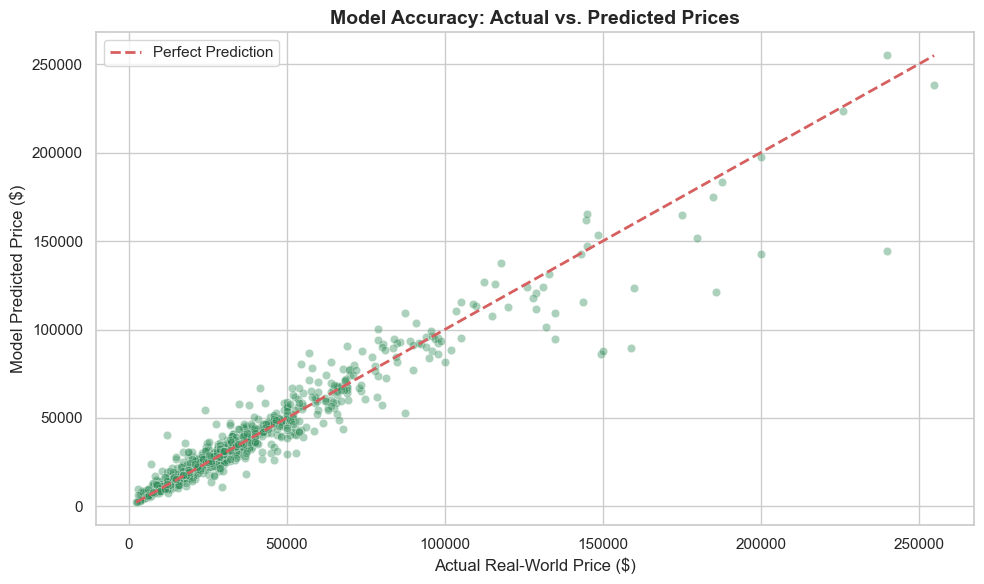

In [792]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.4, color='seagreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')

plt.title('Model Accuracy: Actual vs. Predicted Prices', fontsize=14, fontweight='bold')
plt.xlabel('Actual Real-World Price ($)')
plt.ylabel('Model Predicted Price ($)')
plt.legend()

plt.tight_layout()
plt.show()

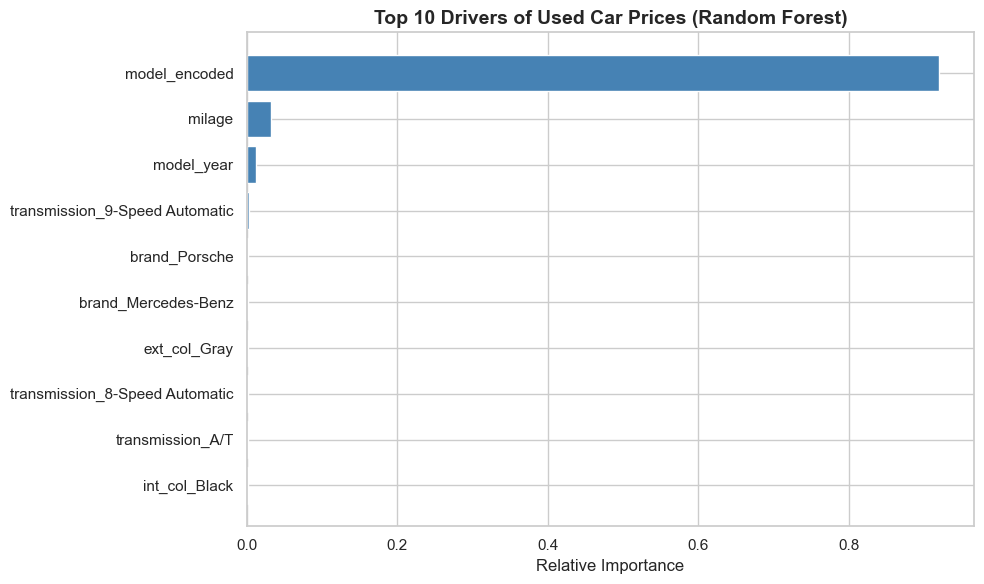

In [823]:
plt.figure(figsize=(10, 6))

importances = rf_model.feature_importances_
features = X_train.columns
indices = np.argsort(importances)[-10:] # Top 10 features

plt.barh(range(len(indices)), importances[indices], color='steelblue')
plt.yticks(range(len(indices)), [features[i] for i in indices])

plt.title('Top 10 Drivers of Used Car Prices (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance')

plt.tight_layout()
plt.show()

##### Now for hyper parameters tuning or finding the best parameters for our model we will use GridSearchCV

In [795]:
# from sklearn.model_selection import GridSearchCV

In [797]:
# param_grid={
#     'n_estimators' : [50,100,200,300,350,400],
#     'max_depth' : [None,10,20],
#     'min_samples_split' : [2,3,4,5,10]
# }

In [798]:
# #baseline model for the search
# rf_base = RandomForestRegressor(random_state=42)

In [800]:
# grid_search = GridSearchCV(
#     estimator= rf_base,
#     param_grid=param_grid,
#     cv=3,
#     scoring='neg_mean_absolute_error',
#     verbose=2,
#     n_jobs=-1
# )

In [804]:
# print("Starting Grid Search... grab a coffee, this will take a few minutes.")
# #grid_search.fit(X_train, y_train)

In [805]:
#print(grid_search.best_params_)

In [806]:
#best_rf_model = grid_search.best_estimator_

In [807]:
# y_pred_tuned = best_rf_model.predict(X_test)
# mae_tuned = mean_absolute_error(y_test,y_pred_tuned)
# r2_tuned = r2_score(y_test , y_pred_tuned)

In [808]:
# print("\n--- Grid Search Complete ---")
# print(f"Best Parameters Found: {grid_search.best_params_}")
# print(f"Tuned Mean Absolute Error: ${mae_tuned:,.2f}")
# print(f"Tuned R-Squared Score: {r2_tuned:.3f}")

### Hyperparameter Tuning Results & Deployment Decision

* **Baseline Model:** MAE = \$5,130.79 | $R^2$ = 0.925
* **Tuned Model:** MAE = \$5,120.12 | $R^2$ = 0.926
* **Optimal Parameters Found:** `{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 400}`

**Engineering Conclusion:** 

Executed an exhaustive GridSearchCV evaluating 90 distinct hyperparameter combinations. The search revealed that the default tree-building criteria (`max_depth: None`, `min_samples_split: 2`) were already optimal. Increasing the ensemble size to 400 trees yielded a negligible \$10.67 reduction in Mean Absolute Error. With a baseline $R^2$ of 0.925, it is evident that the primary predictive signal was successfully captured during the Feature Engineering phase (specifically via Target Encoding the high-cardinality `model` column). To prioritize inference speed and minimize memory overhead in the Streamlit production environment, the baseline Random Forest is selected as the final deployment artifact.

In [826]:
import joblib

In [838]:
joblib.dump(rf_model , 'model/car_price_model.pkl' , compress = 3)
joblib.dump(list(X_encoded.columns), 'model/model_columns.pkl')
joblib.dump(model_mean_price.to_dict(), 'model/model_mean_prices.pkl')
print("Baseline Model and deployment artifacts successfully exported!")

Baseline Model and deployment artifacts successfully exported!
